## Distributions

### カイ2乗分布

非負の実数直線上の確率分布の中で代表的な分布であるガンマ分布の特別な場合としてカイ２乗分布がある。確率変数 $X$ の確率密度関数が$$f_X(x|\alpha,\beta) = \frac{1}{\Gamma(\alpha)}\frac{1}{\beta}\left(\frac{x}{\beta}\right)^{\alpha - 1}e^{-x/\beta}, \quad x > 0$$で与えられているとき、$X$ は**ガンマ分布**に従うといい、この分布を $Ga(\alpha,\beta)$ で表す。また、$\Gamma(\alpha)$ は**ガンマ関数**$$\Gamma(\alpha) = \int^{\infty}_0 y^{\alpha - 1}e^{-y}dy$$で与えられる。

このガンマ分布の特別な場合として、カイ２乗分布は $Ga(n/2,2)$ に対応する。  
$n$ を自然数とするとき、確率変数 $X$ の確率密度関数が$$f_X(x) = \frac{1}{\Gamma(n/2)}\left(\frac{1}{2} \right)^{n/2}x^{n/2-1}\exp\{-x/2\}, \quad x>0$$で与えられているとき、**自由度 $n$ のカイ２乗分布**といい、$\chi^2_n$ で表す。  
<br>
命題１：確率変数 $Z$ が $N(0,1)$ に従うとき、$Z^2$ が $\chi^2_1$ に従う。  
命題２：$\chi^2_m + \chi^2_n = \chi^2_{m+n}$ が成り立つ。  
命題３：$Z_1,...,Z_k$ が互いに独立な確率変数とし、それぞれ $Z_i \sim N(0,1)$ に従うとする。このとき、$Z_1,...,Z_k$ の２乗和は自由度 $k$ のカイ２乗分布に従う。すなわち$$Z_1^2 + ... + Z_k^2 \sim \chi_k^2$$

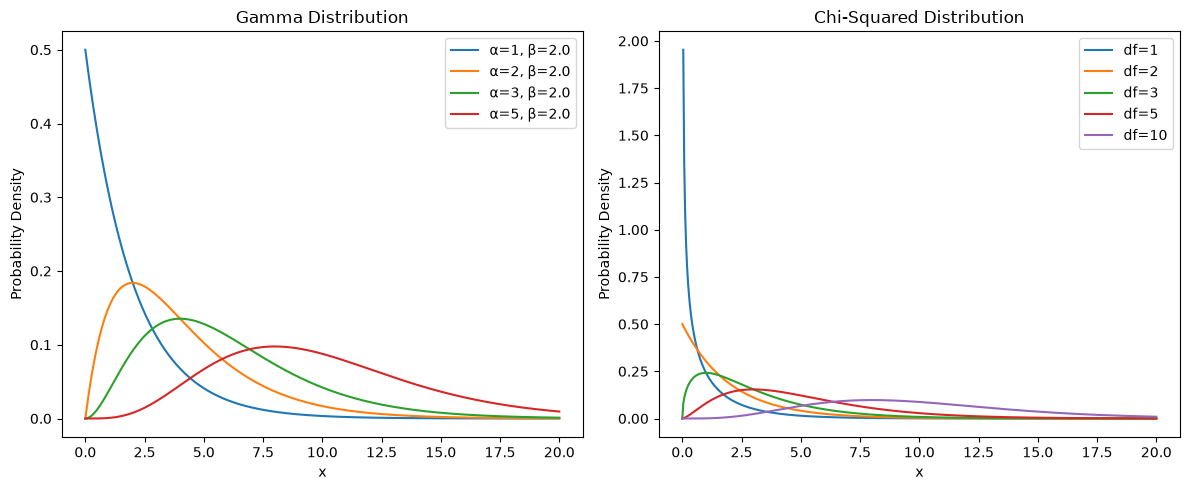

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ガンマ分布
x_gamma = np.linspace(0, 20, 500)
shapes = [1, 2, 3, 5]   # 形状パラメータ α
scale = 2.0   # 尺度パラメータ β

ax = axes[0]
for k in shapes:
    y = stats.gamma.pdf(x_gamma, a=k, scale=scale)
    ax.plot(x_gamma, y, label=f'α={k}, β={scale}')
ax.set_title('Gamma Distribution')
ax.set_xlabel('x')
ax.set_ylabel('Probability Density')
ax.legend()


# カイ２乗分布
x_chi2 = np.linspace(0, 20, 500)
dfs_chi2 = [1, 2, 3, 5, 10]  # 自由度

ax = axes[1]
for df in dfs_chi2:
    y = stats.chi2.pdf(x_chi2, df=df)
    ax.plot(x_chi2, y, label=f'df={df}')
ax.set_title('Chi-Squared Distribution')
ax.set_xlabel('x')
ax.set_ylabel('Probability Density')
ax.legend()

plt.tight_layout()
plt.show()

### t-分布

正規母集団から作られる統計量の分布として代表的なものがカイ２乗分布、t-分布、F-分布である。ここで次のような設定を考える。  
平均 $\mu$、分散 $\sigma^2$ の正規分布に従う母集団（正規母集団）から、ランダムサンプルがとられているとする。$$X_1,...,X_n, i.i.d. \sim N(\mu,\sigma^2)$$標本平均 $\bar{X} = \frac{1}{n}\sum^n_{i=1}X_i$, 不偏分散 $V^2 = \frac{1}{(n-1)}\sum^n_{i=1}(X_i - \bar{X})^2$ について次の定理が成り立つ。  
定理１：$\bar{X}$ と $V^2$ は独立に分布する。  
定理２：$\bar{X} \sim N(\mu,\sigma^2/n)$  
定理３：$(n-1)V^2/\sigma^2 \sim \chi^2_{n-1}$  

このとき、確率変数 $Z = \sqrt{n}(\bar{X} - \mu)/\sigma$ は標準正規分布 $N(0,1)$ に従うことが分かる。ここで $\sigma^2$ の代わりに標本不偏分散 $V^2$ を代入した確率変数 $T = \sqrt{n}(\bar{X} - \mu)/V$ の確率変数を求めてみる。$\mu$ に既知の値が入るとき、この確率変数を t-統計量 といいその分布は仮説検定に使われる。$T$ の分布は $\sigma^2$ の代わりに $V^2$ を用いた分だけ正規分布より裾の厚い分布になっている。  
$U = (n-1)V^2/\sigma^2$ とおくと $U \sim \chi^2_{n-1}$ であり、定理１より $Z$ と $U$ が独立に分布する。このとき、$$T = \sqrt{n}(\bar{X} - \mu)/V = Z/\sqrt{U/(n-1)}$$と書き直すことができる。$T$ の従う分布は自由度 $n-1$ の t-分布 と呼ばれる。$m = n-1$ として、自由度 $m$ の t-分布 の定義を与える。  
<br>
$Z$ と $U$ を独立な確率変数とし、$Z \sim N(0,1), U \sim \chi^2_m$ とする。このとき、$$T = Z/\sqrt{U/m}$$は**自由度 $m$ のスチューデントの t-分布** に従うといい、この分布を $t_m$ で表す。  
<br>
命題１：確率変数 $T$ の確率密度関数は、$-\infty < t < \infty$ に対して$$f_T(t|m) = \frac{\Gamma((m+1)/2)}{\Gamma(m/2)}\frac{1}{\sqrt{\pi m}}\frac{1}{(1 + t^2/m)^{(m+1)/2}}$$で与えられる。  
命題２：$m \to \infty$ とすると、$t_m$ は標準正規分布 $N(0,1)$ に収束する。すなわち、$$\lim_{m\to\infty} f_T(t\mid m) = \phi(t) = \frac{1}{\sqrt{2\pi}}e^{-t^2/2} $$

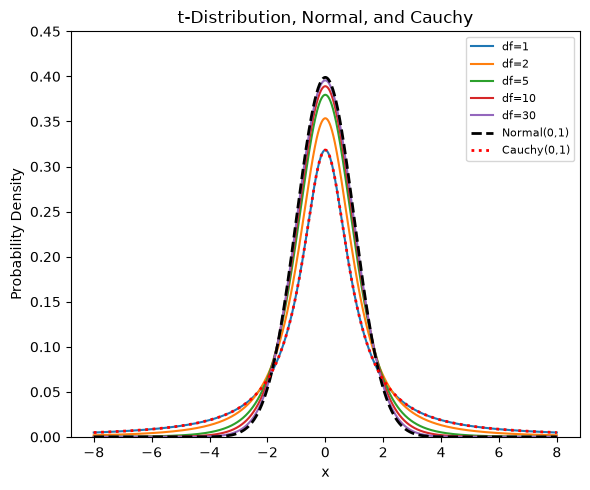

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))

# t-分布
x_t = np.linspace(-8, 8, 1000)
dfs_t = [1, 2, 5, 10, 30]  # 自由度

for df in dfs_t:
    y = stats.t.pdf(x_t, df=df)
    ax.plot(x_t, y, label=f'df={df}')

# 標準正規分布(m → ∞)
ax.plot(x_t, stats.norm.pdf(x_t), 'k--', linewidth=2, label='Normal(0,1)')

# コーシー分布(m = 1)
ax.plot(x_t, stats.cauchy.pdf(x_t), 'r:', linewidth=2, label='Cauchy(0,1)')

ax.set_title('t-Distribution, Normal, and Cauchy')
ax.set_xlabel('x')
ax.set_ylabel('Probability Density')
ax.set_ylim(0, 0.45)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### F-分布

$S$ と $T$ を独立な確率変数とし、$S \sim \chi^2_m, T \sim \chi^2_n$ とする。確率変数 $Y$ を$$Y = \frac{S/m}{T/n}$$とおくとき、$Y$ は**自由度（$m,n$）のスネデッカーの F-分布** に従うといい、その分布を $F_{m,n}$ で表す。  
<br>
$T^2 = Z^2/(U/m)$ と書けるので、$T^2$ は自由度(1,m) の F-分布 に従うことが分かる。  
<br>
命題１：自由度（m,n）の F-分布 に従う確率変数 $Y$ について、その確率密度関数は$$f_Y(y|m,n) = \frac{\Gamma((m+n)/2)}{\Gamma(m/2)\Gamma(n/2)}\frac{(m/n)^{m/2}y^{m/2-1}}{(1 + (m/n)y)^{(m + n)/2}}, \quad y>0$$で与えられる。また $W = S/(S + T)$ は、ベータ分布 $Beta(m/2,n/2)$ に従う。

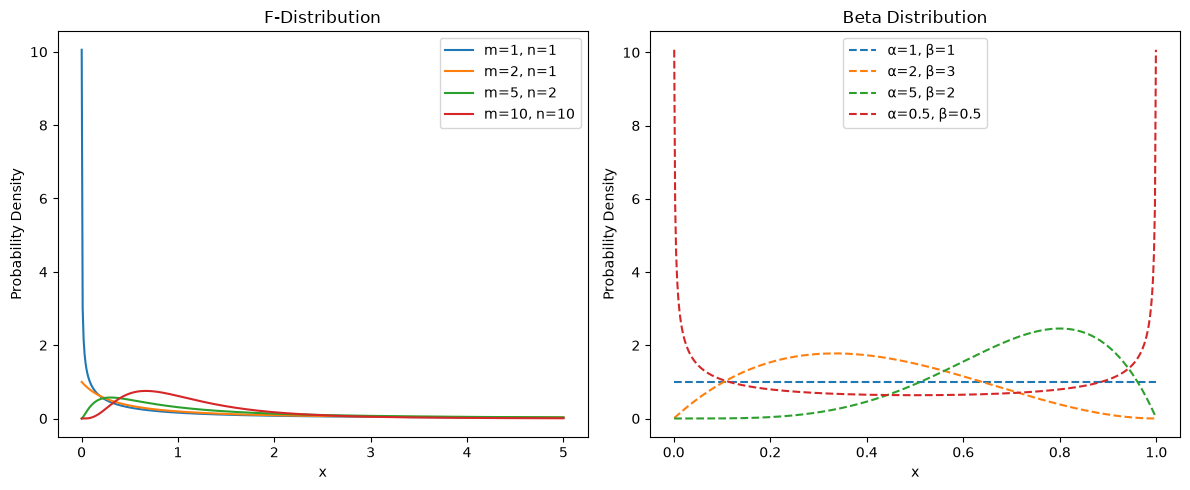

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# F-分布
x_f = np.linspace(0.001, 5, 500)
params_f = [(1, 1), (2, 1), (5, 2), (10, 10)]  # (m, n)

ax = axes[0]
for m, n in params_f:
    y = stats.f.pdf(x_f, dfn=m, dfd=n)
    ax.plot(x_f, y, label=f'm={m}, n={n}')
ax.set_title('F-Distribution')
ax.set_xlabel('x')
ax.set_ylabel('Probability Density')
ax.legend()
    

# ベータ分布
x_beta = np.linspace(0.001, 0.999, 500)
params_beta = [(1, 1), (2, 3), (5, 2), (0.5, 0.5)]

ax = axes[1]
for a, b in params_beta:
    y = stats.beta.pdf(x_beta, a=a, b=b)
    ax.plot(x_beta, y, '--' ,label=f'α={a}, β={b}')
ax.set_title('Beta Distribution')
ax.set_xlabel('x')
ax.set_ylabel('Probability Density')
ax.legend()


plt.tight_layout()
plt.show()